# qrand tutorial: random numbers from a quantum circuit

This notebook walks through the `qrand` library step by step:

1. how a quantum circuit makes random bits
2. turning bits into numbers, and how many you get
3. checking the bits with health tests
4. seeing bias with a random walk, and removing it
5. simulators vs real hardware

It runs locally on Qiskit's built-in simulator. Run it from the repository root after
`pip install -e ".[plot,dev]"`.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()))

import matplotlib.pyplot as plt
from qrand import QuantumRandom, EntropyExhausted, is_hardware, stats

## 1. One circuit, one job

Every qubit gets a Hadamard gate, which puts it in an equal superposition of 0 and 1. Measuring it
gives 0 or 1 with probability ½ each. `QuantumRandom` runs this circuit **once** when you create it,
and every shot adds one bit per qubit to an *entropy pool*.

`backend=None` uses Qiskit's local `BasicSimulator`. On Qollab you pass the `backend` it creates.

In [2]:
qr = QuantumRandom(backend=None, n_qubits=8, shots=512, debias="xor")
print(qr.circuit)
print("raw bits from the job:", len(qr.raw_bits))
print("bits in the pool after xor debiasing:", qr.bits_remaining)

     ┌───┐┌─┐                     
q_0: ┤ H ├┤M├─────────────────────
     ├───┤└╥┘┌─┐                  
q_1: ┤ H ├─╫─┤M├──────────────────
     ├───┤ ║ └╥┘┌─┐               
q_2: ┤ H ├─╫──╫─┤M├───────────────
     ├───┤ ║  ║ └╥┘┌─┐            
q_3: ┤ H ├─╫──╫──╫─┤M├────────────
     ├───┤ ║  ║  ║ └╥┘┌─┐         
q_4: ┤ H ├─╫──╫──╫──╫─┤M├─────────
     ├───┤ ║  ║  ║  ║ └╥┘┌─┐      
q_5: ┤ H ├─╫──╫──╫──╫──╫─┤M├──────
     ├───┤ ║  ║  ║  ║  ║ └╥┘┌─┐   
q_6: ┤ H ├─╫──╫──╫──╫──╫──╫─┤M├───
     ├───┤ ║  ║  ║  ║  ║  ║ └╥┘┌─┐
q_7: ┤ H ├─╫──╫──╫──╫──╫──╫──╫─┤M├
     └───┘ ║  ║  ║  ║  ║  ║  ║ └╥┘
c: 8/══════╩══╩══╩══╩══╩══╩══╩══╩═
           0  1  2  3  4  5  6  7 
raw bits from the job: 4096
bits in the pool after xor debiasing: 2048


## 2. Bits become numbers

Every function takes bits from the pool. Integer functions use rejection sampling, so every value
is equally likely (no modulo bias).

In [3]:
bits = qr.bitstring(16)
print("16 bits      :", bits, "->", int(bits, 2))
print("getrandbits(8):", qr.getrandbits(8), " (0 to 255)")
print("randint(1, 6) :", [qr.randint(1, 6) for _ in range(10)], " (1 to 6, both included)")
print("random()      :", qr.random(), " (0 <= x < 1)")
print("choice        :", qr.choice(["red", "green", "blue"]))
deck = list("ABCDEFGH"); qr.shuffle(deck)
print("shuffle       :", "".join(deck))
print("bits left     :", qr.bits_remaining)

16 bits      : 1001100010110000 -> 39088
getrandbits(8): 68  (0 to 255)
randint(1, 6) : [4, 2, 1, 4, 1, 6, 1, 5, 2, 3]  (1 to 6, both included)
random()      : 0.4325431002109288  (0 <= x < 1)
choice        : blue
shuffle       : CEGDBHFA
bits left     : 1910


### How many numbers does one job give?

A die roll needs 3 bits per try, and values 6 and 7 are rejected, so it costs 4 bits on average.
The default pool (8 qubits × 512 shots, `xor`) holds 2048 bits, so about 512 rolls. When the pool
is empty, qrand raises `EntropyExhausted`. See `docs/USAGE.md` for the full table.

In [4]:
qr = QuantumRandom(n_qubits=8, shots=512, debias="xor")
rolls = []
try:
    while True:
        rolls.append(qr.randint(1, 6))
except EntropyExhausted as e:
    print(f"{len(rolls)} die rolls from one job, then: {e}")

520 die rolls from one job, then: need 3 bits but only 2 left; raise shots/n_qubits


## 3. Health tests

`report()` runs tests in the style of NIST SP 800-22 on the raw and the debiased bits. Each gives a
p-value; `p >= 0.01` passes. It also gives P(1) for every qubit.

In [5]:
qr = QuantumRandom(n_qubits=8, shots=512, debias="xor")
rep = qr.report()
print("P(1) per qubit:", [round(p, 3) for p in rep["per_qubit_p1"]])
for name in ("raw", "debiased"):
    r = rep[name]
    print(f"\n{name}: {r['bits']} bits, share of 1s {r['ones_fraction']:.4f}")
    for key in ("monobit_p", "block_frequency_p", "runs_p", "longest_run_p", "serial_p"):
        print(f"  {key:<18} {r[key]:.3f} {'pass' if r[key] >= 0.01 else 'FAIL'}")

P(1) per qubit: [0.52, 0.492, 0.48, 0.488, 0.48, 0.512, 0.428, 0.486]

raw: 4096 bits, share of 1s 0.4858
  monobit_p          0.070 pass
  block_frequency_p  0.930 pass
  runs_p             0.916 pass
  longest_run_p      0.386 pass
  serial_p           0.129 pass

debiased: 2048 bits, share of 1s 0.4902
  monobit_p          0.377 pass
  block_frequency_p  0.485 pass
  runs_p             0.646 pass
  longest_run_p      0.071 pass
  serial_p           0.152 pass


### How random is this run?

Three measures summarise a run:

- **min-entropy per bit:** how many truly random bits each bit is worth (NIST SP 800-90B
  most-common-value estimate at 99% confidence). Even perfect bits score a little below 1 because
  of the confidence bound, so it is shown next to the best possible score for that many bits.
- **autocorrelation:** the correlation between each bit and the bit 1 to 16 places later. Fair
  bits stay within `±3/√n`.
- **bit image:** every bit as a pixel. Random bits look like TV static.

min-entropy per bit: 0.904 (best possible for 4096 bits: 0.943)
largest correlation: 0.030 (fair range: 0.047)


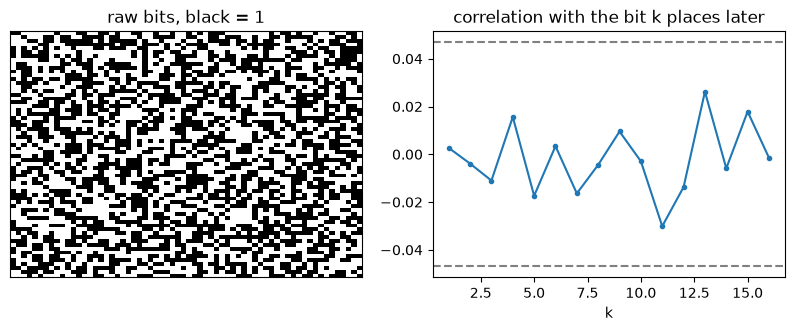

In [6]:
bits = qr.raw_bits
print(f"min-entropy per bit: {stats.min_entropy_per_bit(bits):.3f} "
      f"(best possible for {len(bits)} bits: {stats.ideal_min_entropy_per_bit(len(bits)):.3f})")
corr = stats.autocorrelation(bits)
print(f"largest correlation: {max(map(abs, corr)):.3f} (fair range: {stats.autocorr_limit(len(bits)):.3f})")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
rows = [[int(b) for b in bits[r * 64:(r + 1) * 64]] for r in range(len(bits) // 64)]
ax[0].imshow(rows, cmap="gray_r", interpolation="nearest", aspect="auto")
ax[0].set(title="raw bits, black = 1", xticks=[], yticks=[])
ax[1].plot(range(1, len(corr) + 1), corr, "o-", ms=3)
limit = stats.autocorr_limit(len(bits))
ax[1].axhline(limit, ls="--", color="gray"); ax[1].axhline(-limit, ls="--", color="gray")
ax[1].set(title="correlation with the bit k places later", xlabel="k")
plt.show()

## 4. Seeing bias with a random walk

Real devices are noisy: a qubit can read 1 a little more often than 0. To show what qrand does
with that, here is a small test backend where every qubit reads 1 with probability 0.53. It is a
stand-in for a noisy device, not a real one.

In [7]:
import random

class BiasedBackend:
    """Test backend: every qubit reads 1 with probability p, one bitstring per shot."""
    name = "biased_test_backend"

    def __init__(self, p, seed=1):
        self.p, self.rng = p, random.Random(seed)

    def run(self, circuit, shots, memory):
        n = circuit.num_qubits
        mem = ["".join("1" if self.rng.random() < self.p else "0" for _ in range(n))
               for _ in range(shots)]
        return type("Job", (), {"result": lambda self: type("Result", (), {
            "get_memory": lambda self: mem})()})()

noisy = QuantumRandom(BiasedBackend(0.53), n_qubits=8, shots=512, debias="xor")
print("share of 1s, raw     :", round(stats.ones_fraction(noisy.raw_bits), 4))
print("share of 1s, debiased:", round(stats.ones_fraction(noisy.pool_bits()), 4))

share of 1s, raw     : 0.521
share of 1s, debiased: 0.5146


Each bit is a step: 1 goes up, 0 goes down. A fair walk of `n` steps ends within `±2√n` about
95% of the time (the grey band). A bias toward 1 makes the walk drift by about `(2p − 1) × n`,
which grows faster than the band.

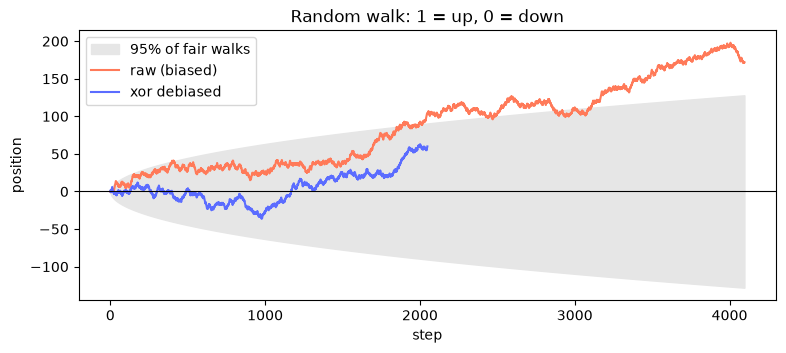

In [8]:
import math

fig, ax = plt.subplots(figsize=(9, 3.5))
n = len(noisy.raw_bits) + 1
band = [2 * math.sqrt(t) for t in range(n)]
ax.fill_between(range(n), [-b for b in band], band, color="0.9", label="95% of fair walks")
ax.plot(stats.random_walk(noisy.raw_bits), color="#ff7a59", label="raw (biased)")
ax.plot(stats.random_walk(noisy.pool_bits()), color="#5b6cff", label="xor debiased")
ax.axhline(0, color="k", lw=0.8)
ax.set(xlabel="step", ylabel="position", title="Random walk: 1 = up, 0 = down")
ax.legend(loc="upper left")
plt.show()

### Comparing the debiasing modes

- `xor` combines neighbouring qubits in each shot and keeps half the bits.
- `von_neumann` compares the same qubit in two shots, keeps a bit only when they differ, and keeps
  about a quarter. It removes bias completely if shots are independent.

In [9]:
for mode in ("none", "xor", "von_neumann"):
    q = QuantumRandom(BiasedBackend(0.53), n_qubits=8, shots=2048, debias=mode)
    bits = q.pool_bits()
    print(f"{mode:<12} {len(bits):>6} bits  share of 1s {stats.ones_fraction(bits):.4f}  "
          f"frequency test p = {stats.monobit_p(bits):.3f}")

none          16384 bits  share of 1s 0.5308  frequency test p = 0.000
xor            8192 bits  share of 1s 0.5011  frequency test p = 0.842
von_neumann    4093 bits  share of 1s 0.4842  frequency test p = 0.044


## 5. Dice from raw vs debiased bits

`dice_from_bits` turns 3-bit chunks into die rolls and `chi2_uniform_p` checks that the faces are
equally common. A small bias barely changes dice counts, which is why the random walk is the better
way to see it.

In [10]:
for name, bits in (("raw", noisy.raw_bits), ("xor", noisy.pool_bits())):
    d = stats.dice_from_bits(bits)
    counts = [d.count(f) for f in range(1, 7)]
    print(f"{name:<4} {len(d):>5} rolls  counts {counts}  chi-square p = {stats.chi2_uniform_p(counts):.3f}")

raw   1001 rolls  counts [149, 175, 161, 182, 163, 171]  chi-square p = 0.538
xor    503 rolls  counts [76, 75, 79, 98, 91, 84]  chi-square p = 0.422


## 6. Is it really quantum? A Bell test

With `bell_test=True`, qrand adds four qubits to the same circuit: two "setting coins" in
superposition and an entangled pair. The coins pick the direction each side is measured in, and
the correlations give the CHSH value `S`. Any classical source gives `S <= 2`; quantum mechanics
predicts `2*sqrt(2) = 2.83`. The Bell qubits never enter the random-number pool.

In [11]:
from qrand import bell

qr = QuantumRandom(n_qubits=8, shots=2048, bell_test=True)
chsh = qr.report()["bell"]
for (a, b), e in chsh["correlations"].items():
    print(f"settings A{a} B{b}: E = {e:+.3f}  (prediction {bell.expected_correlation(a, b):+.3f})")
print(f"S = {chsh['S']:.3f} +/- {chsh['sigma']:.3f}, "
      f"{chsh['sigmas_above_classical']:.1f} standard errors above the classical limit of 2")
print("random-number qubits per shot:", len(qr.raw_shots[0]), "| circuit qubits:", qr.circuit.num_qubits)

settings A0 B0: E = +0.674  (prediction +0.707)
settings A0 B1: E = +0.675  (prediction +0.707)
settings A1 B0: E = +0.708  (prediction +0.707)
settings A1 B1: E = -0.692  (prediction -0.707)
S = 2.749 +/- 0.064, 11.7 standard errors above the classical limit of 2
random-number qubits per shot: 8 | circuit qubits: 12


The test backend from section 4 has no entanglement, so it stays below the classical limit:

In [12]:
classical = QuantumRandom(BiasedBackend(0.5), n_qubits=8, shots=2048, bell_test=True)
print(f"S = {classical.report()['bell']['S']:.3f}  (a classical source can't exceed 2)")

S = 0.012  (a classical source can't exceed 2)


## 7. Simulator or real hardware?

`is_hardware()` recognises IonQ's quantum computers. On a simulator, the bits are simulated quantum
randomness; only real hardware is physically random. On Qollab, hardware needs no code change and no
API key: pick an IonQ quantum computer in **Select QPU** and approve the credit cost.

In [13]:
print("built-in simulator is hardware?", is_hardware(QuantumRandom(shots=64).backend))

built-in simulator is hardware? False


## Next steps

- `python main.py` runs the full demo with all charts.
- `docs/USAGE.md` lists every function, its range and its bit cost.
- `docs/DEVICE_RESULTS.md` collects results from different Qollab backends.